In [1]:
import pandas as pd
import numpy as np
import math
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
import warnings
import operator as op
from natsort import natsort_key
warnings.filterwarnings('ignore')

df = pd.read_csv('output_08-10-2026_09-03-11.csv',
                 parse_dates=["start_time", "end_time"],
                 date_format="%m-%d-%Y %H:%M:%S")

df = df.loc[df['inc'] != 4]

# if you need another csv then:
df_temp = pd.read_csv('output_16-10-2026_12-44-43.csv',
                      parse_dates=["start_time", "end_time"],
                 date_format="%m-%d-%Y %H:%M:%S")
df = pd.concat([df, df_temp], ignore_index=True)

df['exp_parameters'] = df['exp_parameters'].astype(str).str.strip()

word_count = df['exp_parameters'].str.split().str.len()

df.loc[word_count == 1, 'exp_parameters'] = df['exp_parameters'] + ' default'

df = df.sort_values('exp_parameters', key=natsort_key)


print(f'Shape: {df.shape}')
print(df['exp_parameters'].unique())



Shape: (5100, 52)
['Cable default' 'Cable inc' 'Cable mnp' 'Cable mps' 'Cable ptc'
 'Cable sdt' 'Fiber default' 'Fiber inc' 'Fiber mnp' 'Fiber mps'
 'Fiber ptc' 'Fiber sdt' 'VDSL default' 'VDSL inc' 'VDSL mnp' 'VDSL mps'
 'VDSL ptc' 'VDSL sdt']


In [2]:

rpm_cols = [c for c in df.columns if 'rpm' in c.lower()]

fieldnames = ['exp_parameters']
environment_parameters = ['dl_capacity', 'ul_capacity', 'dl_delay', 'ul_delay']

rpm_parameters = ['id', 'inc', 'inp', 'mad', 'mnp', 'mps', 'p', 'ptc', 'sdt', 'timeout', 'tmp']

dl_test_output = ['dl_stable_throughput', 'dl_stable_responsiveness', 'dl_throughput', 'dl_connections',
                   'dl_max_path_mtu', 'dl_max_send_mss', 'dl_max_recv_mss', 'dl_retransmissions',
                   'dl_reorder', 'dl_avg_rtt', 'dl_rpm_p', 'dl_rpm_trimmed']

ul_test_output = ['ul_stable_throughput', 'ul_stable_responsiveness', 'ul_throughput', 'ul_connections',
                   'ul_max_path_mtu', 'ul_max_send_mss', 'ul_max_recv_mss', 'ul_retransmissions',
                   'ul_reorder', 'ul_avg_rtt', 'ul_rpm_p', 'ul_rpm_trimmed']

final_test_output = ['final_rpm_p', 'final_rpm_trimmed']

relative_test_output = ['ub_base_rpm_p', 'ub_base_rpm_trimmed', 'base_rpm_p', 'base_rpm_trimmed',
                         'wc_effect_p', 'wc_effect_trimmed']
misc = ['iteration', 'start_time', 'end_time']

outputs = dl_test_output + ul_test_output + final_test_output + relative_test_output

not_relevant = ["mtu", "mss"]

outputs_for_plots = [
    item for item in outputs 
    if not any(sub in item for sub in not_relevant)
]


bool_cols = ['dl_stable_throughput', 'dl_stable_responsiveness',
             'ul_stable_throughput', 'ul_stable_responsiveness']

relevant_parameters = ['intervalDuration', 'connectionsPerInterval', 'connectionsInitial', 'movingAverageDistance', 'maxParallelConnections', 
                       'probesPerSecond', 'percentageOfResults', 'capacityOfProbes', 'stabilityCutoff', 'calculationTime']
for c in bool_cols:
    if c in df.columns and df[c].dtype == object:
        df[c] = df[c].map({'True': True, 'False': False})

environments = ['VDSL', 'Cable', 'Fiber']

# rename the parameters to something readable:
rename_map = {
    'id': 'intervalDuration',
    'inc': 'connectionsPerInterval', 
    'inp': 'connectionsInitial', 
    'mad': 'movingAverageDistance', 
    'mnp': 'maxParallelConnections', 
    'mps': 'probesPerSecond', 
    'p': 'percentageOfResults', 
    'ptc': 'capacityOfProbes', 
    'sdt': 'stabilityCutoff', 
    'timeout': 'calculationTime',
    'tmp': 'trimPercentage'
}

default_values = {
    'intervalDuration': 5,
    'connectionsPerInterval': 1,
    'connectionsInitial': 1,
    'movingAverageDistance': 4,
    'maxParallelConnections': 16,
    'probesPerSecond': 100,
    'percentageOfResults': 90,
    'capacityOfProbes': 0.05,
    'stabilityCutoff': 5,
    'calculationTime': 20,
    'trimPercentage': 5
}

df = df.rename(columns=rename_map)
for old_name, new_name in rename_map.items():
    # '\b' ensures we match the exact word, not parts of other words
    regex_pattern = rf'\b{old_name}\b'
    
    df['exp_parameters'] = df['exp_parameters'].str.replace(regex_pattern, new_name, regex=True)

parameter_ranges = {}

for param in relevant_parameters:
    parameter_ranges[param] = df[param].unique()

df.head()

,exp_parameters,dl_capacity,ul_capacity,dl_delay,ul_delay,intervalDuration,connectionsPerInterval,connectionsInitial,movingAverageDistance,maxParallelConnections,...,ub_base_rpm_p,ub_base_rpm_trimmed,base_rpm_p,base_rpm_trimmed,wc_effect_p,wc_effect_trimmed,iteration,start_time,end_time,result_time
3700,Cable default,250,50,10,10,1,1,1,4,16,...,2839,2856,2839,2856,1,6,79,2026-10-10 09:10:13,NaT,10-10-2026 09:11:51
3773,Cable default,250,50,10,10,1,1,1,4,16,...,2843,2857,2842,2857,2,7,65,2026-10-10 08:46:33,NaT,10-10-2026 08:48:11
3772,Cable default,250,50,10,10,1,1,1,4,16,...,2842,2857,2841,2857,1,6,25,2026-10-10 07:38:53,NaT,10-10-2026 07:40:31
3771,Cable default,250,50,10,10,1,1,1,4,16,...,2839,2856,2838,2856,1,6,6,2026-10-10 07:06:45,NaT,10-10-2026 07:08:23
3770,Cable default,250,50,10,10,1,1,1,4,16,...,2784,2834,2790,2846,1,5,90,2026-10-10 09:28:49,NaT,10-10-2026 09:30:27


In [3]:
# ...existing code...
import re

# include all tunable parameter columns that exist in df
param_cols = [c for c in rename_map.values() if c in df.columns]

def _fmt(v):
    if pd.isna(v):
        return "NA"
    if isinstance(v, (int, np.integer)):
        return str(v)
    if isinstance(v, (float, np.floating)) and float(v).is_integer():
        return str(int(v))
    return str(v)

def rebuild_exp_parameters(row):
    text = str(row["exp_parameters"])

    # 1) network
    network = next(
        (n for n in environments if re.search(rf"\b{re.escape(n)}\b", text, flags=re.IGNORECASE)),
        "UnknownNetwork"
    )

    # 2) parameter names present in text
    used_params = [
        p for p in param_cols
        if re.search(rf"\b{re.escape(p)}\b", text)
    ]

    # default/no explicit parameter
    if not used_params:
        if re.search(r"\bdefault\b", text, flags=re.IGNORECASE):
            return f"{network} default"
        return network

    # 3) attach values from columns
    parts = [f"{p} {_fmt(row[p])}" for p in used_params]
    return f"{network} " + " ".join(parts)

df["exp_parameters"] = df.apply(rebuild_exp_parameters, axis=1)

print(df["exp_parameters"].unique())
# ...existing code...

['Cable default' 'Cable connectionsPerInterval 5'
 'Cable connectionsPerInterval 3' 'Cable connectionsPerInterval 4'
 'Cable connectionsPerInterval 2' 'Cable maxParallelConnections 20'
 'Cable maxParallelConnections 8' 'Cable maxParallelConnections 12'
 'Cable probesPerSecond 120' 'Cable probesPerSecond 80'
 'Cable probesPerSecond 60' 'Cable probesPerSecond 140'
 'Cable probesPerSecond 40' 'Cable capacityOfProbes 0.01'
 'Cable capacityOfProbes 0.1' 'Cable stabilityCutoff 7'
 'Cable stabilityCutoff 3' 'Fiber default'
 'Fiber connectionsPerInterval 3' 'Fiber connectionsPerInterval 2'
 'Fiber connectionsPerInterval 4' 'Fiber connectionsPerInterval 5'
 'Fiber maxParallelConnections 20' 'Fiber maxParallelConnections 8'
 'Fiber maxParallelConnections 12' 'Fiber probesPerSecond 40'
 'Fiber probesPerSecond 120' 'Fiber probesPerSecond 140'
 'Fiber probesPerSecond 80' 'Fiber probesPerSecond 60'
 'Fiber capacityOfProbes 0.01' 'Fiber capacityOfProbes 0.1'
 'Fiber stabilityCutoff 7' 'Fiber stabilit

In [4]:
# cleanup the dataset
is_nan = df[rpm_cols].isna()
is_inf = df[rpm_cols].isin([np.inf, -np.inf])
invalid_rpm = is_nan | is_inf

df_clean = df[~invalid_rpm.any(axis=1)].copy()

df_clean = df_clean.sort_values('exp_parameters', key=natsort_key)

df_clean = df_clean.reset_index(drop=True)

# Standard deviation of each experiment

In [5]:
# we separate the clean df into 3 dfs for each environment

exp_col = df_clean["exp_parameters"].astype(str)

df_clean_vdsl = df_clean[exp_col.str.contains(r"\bVDSL\b", case=False, na=False)].copy()
df_clean_cable = df_clean[exp_col.str.contains(r"\bCable\b", case=False, na=False)].copy()
df_clean_fiber = df_clean[exp_col.str.contains(r"\bFiber\b", case=False, na=False)].copy()

print("VDSL:", df_clean_vdsl.shape)
print("Cable:", df_clean_cable.shape)
print("Fiber:", df_clean_fiber.shape)

df_clean_vdsl = df_clean[exp_col.str.contains(r"\bVDSL\b", case=False, na=False)].copy()
df_clean_cable = df_clean[exp_col.str.contains(r"\bCable\b", case=False, na=False)].copy()
df_clean_fiber = df_clean[exp_col.str.contains(r"\bFiber\b", case=False, na=False)].copy()

VDSL: (1700, 52)
Cable: (1700, 52)
Fiber: (1700, 52)


In [6]:

env_dfs = {
    "VDSL": df_clean_vdsl,
    "Cable": df_clean_cable,
    "Fiber": df_clean_fiber,
}

for env_name, env_df in env_dfs.items():
    rpm_trimmed_cols = [c for c in env_df.columns if "rpm_trimmed" in c.lower()]
    if not rpm_trimmed_cols:
        print(f"[{env_name}] No columns containing 'rpm_trimmed' were found.")
        continue

    df_numeric = env_df[rpm_trimmed_cols].apply(pd.to_numeric, errors="coerce")

    stats = (
        df_numeric.apply(
            lambda s: pd.Series({
                "mean": s.mean(),
                "median": s.median(),
                "std": s.std(),
                "variance": s.var(),
                "min": s.min(),
                "max": s.max(),
                "count": s.count(),
                "p25": s.quantile(0.25),
                "p75": s.quantile(0.75),
                "iqr": s.quantile(0.75) - s.quantile(0.25),
            })
        )
        .T
        .round(4)
    )

    print(f"\n=== {env_name} ===")
    display(stats)



=== VDSL ===


,mean,median,std,variance,min,max,count,p25,p75,iqr
dl_rpm_trimmed,689.2588,731.0,105.7323,11179.3244,340.0,879.0,1700.0,683.0,749.0,66.0
ul_rpm_trimmed,119.7541,76.0,117.7506,13865.2108,33.0,537.0,1700.0,65.0,105.0,40.0
final_rpm_trimmed,228.3900,185.0,123.5220,15257.6942,107.0,636.0,1700.0,168.0,213.0,45.0
ub_base_rpm_trimmed,5469.5053,5473.0,33.9930,1155.5238,5220.0,5504.0,1700.0,5468.0,5479.0,11.0
base_rpm_trimmed,5469.5953,5473.0,34.1185,1164.0715,5222.0,5506.0,1700.0,5468.0,5480.0,12.0



=== Cable ===


,mean,median,std,variance,min,max,count,p25,p75,iqr
dl_rpm_trimmed,700.0476,767.0,119.0934,14183.2332,448.0,901.0,1700.0,646.75,795.00,148.25
ul_rpm_trimmed,107.7641,71.0,85.6154,7329.9932,31.0,418.0,1700.0,61.00,119.00,58.00
final_rpm_trimmed,216.3641,179.0,98.6803,9737.8044,112.0,542.0,1700.0,159.00,227.25,68.25
ub_base_rpm_trimmed,2859.8006,2858.0,4.1990,17.6312,2834.0,2873.0,1700.0,2857.00,2861.00,4.00
base_rpm_trimmed,2859.4982,2858.0,4.3683,19.0824,2846.0,2873.0,1700.0,2856.00,2861.00,5.00



=== Fiber ===


,mean,median,std,variance,min,max,count,p25,p75,iqr
dl_rpm_trimmed,1194.7559,1218.0,184.1367,33906.3318,742.0,1654.0,1700.0,1104.75,1336.0,231.25
ul_rpm_trimmed,1170.6671,1264.0,231.8406,53750.0574,350.0,1660.0,1700.0,977.75,1329.0,351.25
final_rpm_trimmed,1145.7876,1206.5,180.8420,32703.8130,630.0,1501.0,1700.0,1035.00,1274.0,239.00
ub_base_rpm_trimmed,6714.0294,6717.0,16.9082,285.8861,6655.0,6751.0,1700.0,6708.00,6725.0,17.00
base_rpm_trimmed,6713.7282,6717.0,16.7721,281.3022,6657.0,6749.0,1700.0,6708.00,6725.0,17.00


## for each unique experiment

In [7]:
df_clean = df_clean.sort_values(by='exp_parameters')

for exp in df_clean['exp_parameters'].dropna().unique():
    df_exp = df_clean.loc[df_clean['exp_parameters'] == exp]
    df_numeric = df_exp[rpm_trimmed_cols].apply(pd.to_numeric, errors='coerce')

    stats = (
        df_numeric.apply(
            lambda s: pd.Series({
                'mean': s.mean(),
                'median': s.median(),
                'std': s.std(),
                'variance': s.var(),
                'min': s.min(),
                'max': s.max(),
                'count': s.count(),
                'p25': s.quantile(0.25),
                'p75': s.quantile(0.75),
                'iqr': s.quantile(0.75) - s.quantile(0.25)
            })
        )
        .T
        .round(4)
    )

    print(f"\n=== exp_parameters: {exp} ===")
    print(stats.to_string())


=== exp_parameters: Cable capacityOfProbes 0.01 ===
                        mean  median      std   variance     min     max  count      p25      p75    iqr
dl_rpm_trimmed        761.01   786.0  55.2576  3053.4039   637.0   855.0  100.0   716.75   798.00  81.25
ul_rpm_trimmed         66.57    66.5   7.0714    50.0052    50.0    88.0  100.0    61.75    72.00  10.25
final_rpm_trimmed     170.65   168.0  15.6627   245.3207   137.0   214.0  100.0   159.00   180.25  21.25
ub_base_rpm_trimmed  2857.62  2858.0   1.4687     2.1572  2854.0  2862.0  100.0  2856.75  2859.00   2.25
base_rpm_trimmed     2857.02  2857.0   1.5698     2.4642  2854.0  2860.0  100.0  2856.00  2858.00   2.00

=== exp_parameters: Cable capacityOfProbes 0.1 ===
                        mean  median      std   variance     min     max  count      p25      p75     iqr
dl_rpm_trimmed        753.89   779.5  62.5728  3915.3514   581.0   860.0  100.0   679.75   799.25  119.50
ul_rpm_trimmed         67.01    66.0   6.8439    46.8

## heatmap of the stds

In [8]:
rpm_trimmed_cols = [c for c in df_clean.columns if 'rpm_trimmed' in c.lower()]
if not rpm_trimmed_cols:
    raise ValueError("No columns containing 'rpm_trimmed' were found.")

df_numeric = df_clean[rpm_trimmed_cols].apply(pd.to_numeric, errors='coerce')
exp_names = df_clean['exp_parameters'].dropna().unique()

# 1) std summary table
std_table = []
for exp in exp_names:
    row = (
        df_numeric.loc[df_clean['exp_parameters'] == exp]
        .std(ddof=1, skipna=True)
    )
    std_table.append(row)

std_df = pd.concat(std_table, axis=1).T
std_df.index = exp_names
std_df = std_df.round(4)

print("Standard deviation per experiment and rpm_trimmed column:")
display(std_df)

Standard deviation per experiment and rpm_trimmed column:


,dl_rpm_trimmed,ul_rpm_trimmed,final_rpm_trimmed,ub_base_rpm_trimmed,base_rpm_trimmed
Cable capacityOfProbes 0.01,55.2576,7.0714,15.6627,1.4687,1.5698
Cable capacityOfProbes 0.1,62.5728,6.8439,14.8083,1.4158,1.5487
Cable connectionsPerInterval 2,30.3035,8.9245,14.7326,1.6107,1.6049
Cable connectionsPerInterval 3,14.3777,10.5909,14.2435,1.4269,1.5978
Cable connectionsPerInterval 4,10.0596,11.6104,14.0924,1.5217,1.4865
Cable connectionsPerInterval 5,14.6381,13.2835,14.3658,1.5918,1.7203
Cable default,59.8204,7.1521,15.7433,2.7538,1.8743
Cable maxParallelConnections 12,51.6176,6.7580,15.4186,1.5864,1.9128
Cable maxParallelConnections 20,54.0386,7.1682,15.5669,1.4870,1.4489
Cable maxParallelConnections 8,60.7991,7.8482,14.0923,1.5235,1.7234


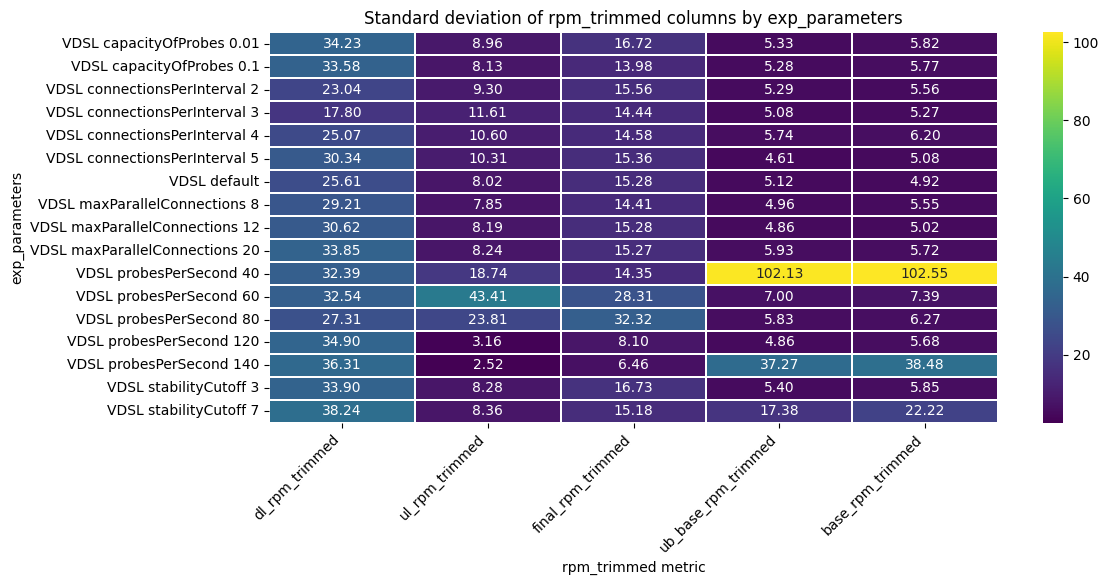

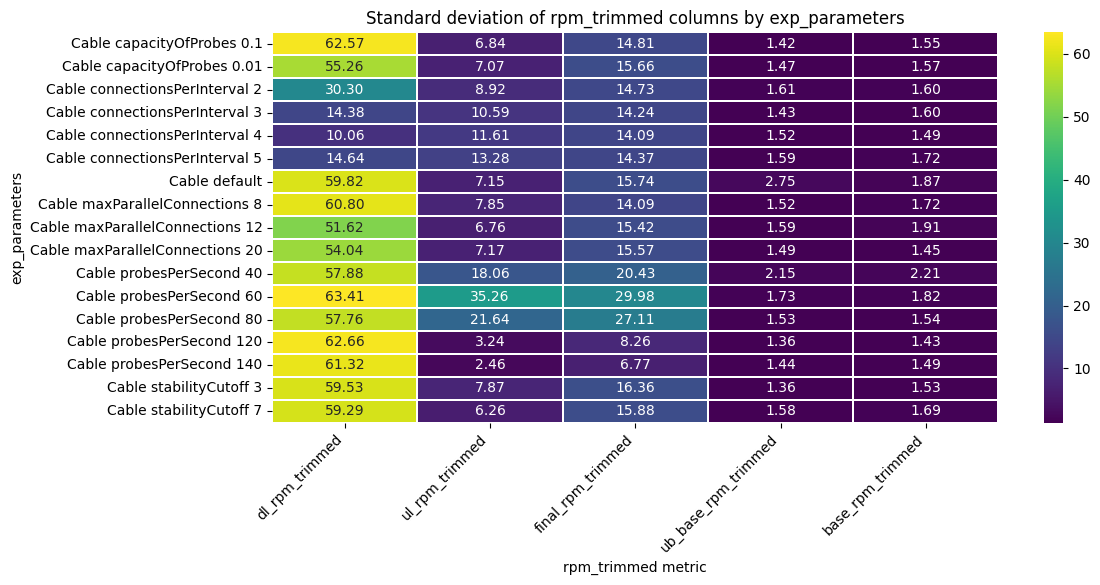

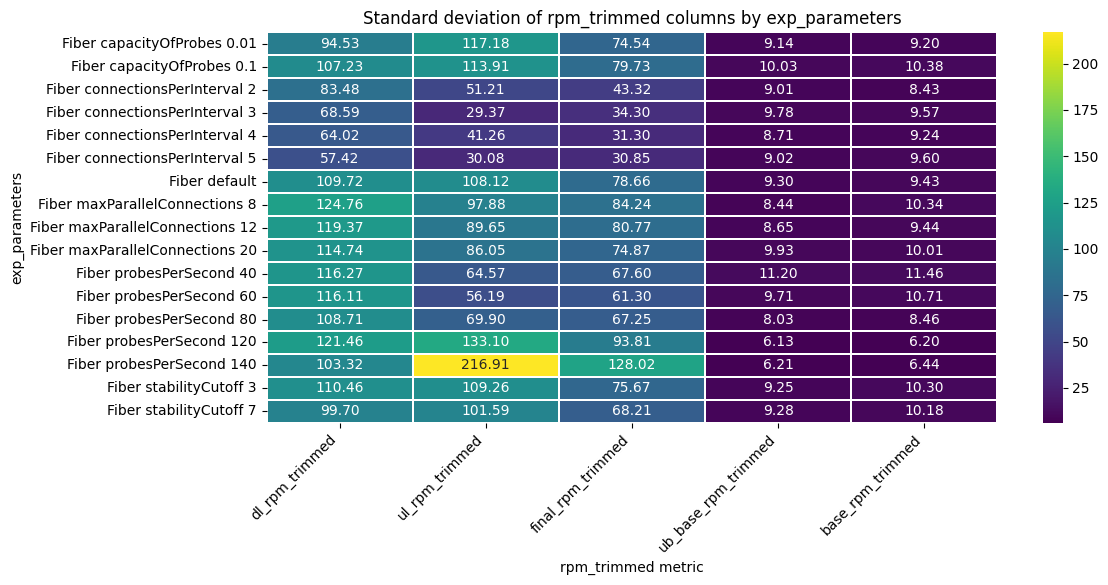

In [9]:
for env_df in env_dfs.values():   

    rpm_trimmed_cols = [c for c in env_df.columns if 'rpm_trimmed' in c.lower()]
    df_numeric = env_df[rpm_trimmed_cols].apply(pd.to_numeric, errors='coerce')

    std_table = []
    for exp in env_df['exp_parameters'].dropna().unique():
        row = df_numeric.loc[env_df['exp_parameters'] == exp].std(ddof=1, skipna=True)
        std_table.append(row)

    std_df = pd.concat(std_table, axis=1).T
    std_df.index = env_df['exp_parameters'].dropna().unique()
    std_df = std_df.round(4)

    plt.figure(figsize=(12, max(5, len(std_df) * 0.35)))
    sns.heatmap(std_df, cmap="viridis", annot=True, fmt=".2f", linewidths=0.1)
    plt.title("Standard deviation of rpm_trimmed columns by exp_parameters")
    plt.xlabel("rpm_trimmed metric")
    plt.ylabel("exp_parameters")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()